In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

In [2]:
CLAIMS_FILEPATH = 'data/claims_claims.csv'
# GID_SRC = 'https://seshat.datasd.org/get_it_done_reports'
GID_SRC = 'data'
REFFERALS_CSV = 'data/referral data for UCSD-2026-11-02-23-09-16.csv'
YEARS = np.arange(2016, 2026+1)
DATA_AS_OF = '2026-11-18'

In [3]:
pub_cols = [
    'service_request_id','service_request_parent_id','date_requested','date_closed','status',
    'case_record_type','service_name','public_description','lat','lng','case_age_days'
    ]

closed = pd.concat([pd.read_csv(f'{GID_SRC}/get_it_done_requests_closed_{y}_datasd.csv', usecols=pub_cols, low_memory=False) for y in YEARS], ignore_index=True)
open_ = pd.read_csv(f'{GID_SRC}/get_it_done_requests_open_datasd.csv', usecols=pub_cols)

public = pd.concat([closed, open_], ignore_index=True).drop_duplicates('service_request_id')
public = public[public['service_request_parent_id'].isna()].drop(columns='service_request_parent_id')
public['date_requested'] = pd.to_datetime(public['date_requested']).dt.normalize()
public['date_closed'] = pd.to_datetime(public['date_closed']).dt.normalize()
public = public.dropna(subset=['lat', 'lng', 'service_name'])
public = public[(public['lat'] != 0) & (public['lng'] != 0)].reset_index(drop=True)

associations = pd.read_csv('associated_claims_15.0_m.csv')
associations = associations[~(associations['service_request_id_gid'].isin([3352145, 3556782]))]

In [4]:
routing_cols_to_keep = {'CASENUMBER':'service_request_id','ORIGINAL_TYPE':'original_type','suggested_category':'suggested_category'}
agreements = pd.read_csv('exact_agreement_cases.csv', usecols=list(routing_cols_to_keep)).rename(columns=routing_cols_to_keep)
agreements = agreements.merge(public[['service_request_id','case_record_type','service_name','date_requested','date_closed','status']], on='service_request_id', how='left')
agreements = agreements.dropna(subset=['case_record_type','service_name','date_requested'])

In [5]:
id_to_drop = agreements.loc[(agreements['original_type'] == agreements['service_name']), 'service_request_id'].values

In [6]:
routing_cols_to_keep.update({'label_name':'label'})
labeled_cases = pd.read_csv('data/labeled_routing_dataset.csv', usecols=routing_cols_to_keep).rename(columns=routing_cols_to_keep)
labeled_cases = labeled_cases[~(labeled_cases['service_request_id'].isin(id_to_drop))]
labeled_cases = labeled_cases.merge(public[['service_request_id','case_record_type','service_name','date_requested','date_closed','status','case_age_days']], on='service_request_id', how='left')

Some service requests are associated to multiple liabilities.

In [7]:
chk = associations.groupby('service_request_id_gid')['claim_id'].nunique().reset_index()
many_assoc = chk.loc[chk['claim_id'] > 1, 'service_request_id_gid'].values
print('number of service requests associated to multiple liabilities:',len(many_assoc))

number of service requests associated to multiple liabilities: 53


In [8]:
print('what and how many losses are associated to those service requests:', )
associations[associations['service_request_id_gid'].isin(many_assoc)].groupby('service_request_id_gid')['loss_code_desc'].value_counts()

what and how many losses are associated to those service requests:


service_request_id_gid  loss_code_desc              
80547                   Maint Of Road (Potholes)        2
81402                   Maint Of Road (Potholes)        2
121021                  Maint Of Road (Potholes)        7
126862                  Maint Of Road (Potholes)        2
129702                  Maint Of Road (Potholes)        2
130213                  Maint Of Road (Potholes)        3
131350                  Slip & Fall                     1
                        Trip & Fall                     1
132574                  Maint Of Road (Potholes)        4
133618                  Maint Of Road (Potholes)        4
133902                  Maint Of Road (Potholes)        4
136986                  Maint Of Road (Potholes)        3
142141                  Maint Of Road (Potholes)        2
144649                  Maint Of Road (Potholes)        2
145325                  Maint Of Road (Potholes)        5
152545                  Maint Of Road (Potholes)        3
170830             

In [9]:
potholes = associations[associations['service_request_id_gid'] == 121021]\
    .groupby('service_request_id_gid')[['claim_id','loss_code_desc','service_name','incident_date','date_requested','date_closed_gid','incurred_total']]\
        .agg(
            n_claims=('claim_id','count'),
            loss_desc=('loss_code_desc', lambda t: ', '.join(list(set(t)))),
            service_type=('service_name', lambda t: t.mode().tolist()[0]),
            earliest_incident_date=('incident_date','min'),
            latest_incident_date=('incident_date','max'),
            date_requested=('date_requested','min'),
            date_closed_gid=('date_closed_gid','min'),
            overall_incurred_total=('incurred_total','sum')
    )

potholes

,n_claims,loss_desc,service_type,earliest_incident_date,latest_incident_date,date_requested,date_closed_gid,overall_incurred_total
service_request_id_gid,,,,,,,,
121021,7,Maint Of Road (Potholes),Pothole,2016-12-25,2017-02-03,2016-11-28,2017-05-25,872.73


In [10]:
storm_drains = associations[associations['service_request_id_gid'] == 2599576]\
    .groupby('service_request_id_gid')[['claim_id','loss_code_desc','service_name','incident_date','date_requested','date_closed_gid','incurred_total','public_description_gid']]\
        .agg(
            n_claims=('claim_id','count'),
            loss_desc=('loss_code_desc', lambda t: ', '.join(list(set(t)))),
            service_type=('service_name', lambda t: t.mode().tolist()[0]),
            earliest_incident_date=('incident_date','min'),
            latest_incident_date=('incident_date','max'),
            date_requested=('date_requested','min'),
            date_closed_gid=('date_closed_gid','min'),
            overall_incurred_total=('incurred_total','sum'),
    )
storm_drains

,n_claims,loss_desc,service_type,earliest_incident_date,latest_incident_date,date_requested,date_closed_gid,overall_incurred_total
service_request_id_gid,,,,,,,,
2599576,3,Storm Drains,Stormwater,2024-01-22,2024-01-22,2019-05-22,2025-08-28,15000.0


In [11]:
associations['service_request_id_gid'].isin(agreements['service_request_id'].values).sum()

np.int64(0)

`cases_2026_11_16.csv` is too large to load locally. To account for this, we ran this code to export the necessary columns.

```python
private_cols = ['CASENUMBER','ORIGINAL_TYPE','CURRENT_TYPE','STATUS']
private_data = pd.read_csv('data/cases_2026_11_16.csv', usecols=private_cols, low_memory=False)
private_data.to_csv('data/cases_type.csv', index=False)
```

In [12]:
private_data = pd.read_csv('data/cases_type.csv', low_memory=False)

In [13]:
assoc = associations.merge(private_data, left_on='service_request_id_gid', right_on='CASENUMBER', how='left')

In [14]:
assoc = assoc[(assoc['CURRENT_TYPE'] != assoc['ORIGINAL_TYPE']) & (assoc['ORIGINAL_TYPE'].notna())]
assoc = assoc[~((assoc['CURRENT_TYPE'] == 'Sidewalk Repair Issue') & (assoc['ORIGINAL_TYPE'] == 'Sidewalk'))]

In [15]:
assoc = assoc[['loss_code_desc', 'service_name', 'work_timing', 'incident_date', 'date_requested', 'date_closed_gid', 'incurred_total', 'CURRENT_TYPE', 'ORIGINAL_TYPE']]

In [16]:
assoc.shape[0]

27

In [17]:
assoc['incurred_total'].sum()

np.float64(158301.83)

In [18]:
labeled_cases['label'].value_counts()

label
correctly_routed    3000
likely_misrouted    2773
Name: count, dtype: int64

In [19]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from scipy import stats

In [20]:
# style (slide template)
NAVY, ORANGE, SLATE = '#17304A', '#D95F02', '#6B7B8C'
LIGHT, BG, GRID = '#C9D2D9', '#F7FAFA', '#DDE3E6'
MIN_CELL = 10

def new_chart():
    fig, ax = plt.subplots(figsize=(8.6, 4.3), facecolor=BG)
    ax.set_facecolor(BG)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color(SLATE)
    ax.tick_params(labelsize=12, colors='black')
    ax.set_axisbelow(True)
    return fig, ax

def footnote(fig, text):
    fig.text(0.01, 0.01, text, fontsize=10, color=SLATE)
    fig.tight_layout(rect=(0, 0.05, 1, 1))

def money(v):
    return f'${v / 1e6:,.2f}M' if v >= 1e6 else f'${v / 1e3:,.0f}K'

In [21]:
liab = associations.copy()
for c in ['incident_date', 'date_requested']:
    liab[c] = pd.to_datetime(liab[c])
assert liab['claim_id'].is_unique

types = private_data[['CASENUMBER', 'ORIGINAL_TYPE', 'CURRENT_TYPE']].drop_duplicates('CASENUMBER')
mr = liab.merge(types, left_on='service_request_id_gid', right_on='CASENUMBER', how='left')
mr['misrouted'] = (
    mr['ORIGINAL_TYPE'].notna()
    & (mr['CURRENT_TYPE'] != mr['ORIGINAL_TYPE'])
    & ~((mr['CURRENT_TYPE'] == 'Sidewalk Repair Issue') & (mr['ORIGINAL_TYPE'] == 'Sidewalk'))
    & ~mr['service_request_id_gid'].isin([3352145, 3556782]))
liab['misrouted'] = liab['claim_id'].map(mr.set_index('claim_id')['misrouted']).fillna(False).astype(bool)

eligible = pd.read_csv('eligible_claims.csv')
print(f'associated claims: {len(liab)} of {len(eligible)} eligible ({len(liab) / len(eligible):.1%}) '
      f'| distinct requests: {liab["service_request_id_gid"].nunique()}')
print(f"associated share of eligible incurred: {liab['incurred_total'].sum() / eligible['incurred_total'].sum():.1%}")
print(f"misrouted claims: {int(liab['misrouted'].sum())} | "
      f"distinct requests: {liab.loc[liab['misrouted'], 'service_request_id_gid'].nunique()} | "
      f"incurred: ${liab.loc[liab['misrouted'], 'incurred_total'].sum():,.2f}")

associated claims: 517 of 8130 eligible (6.4%) | distinct requests: 434
associated share of eligible incurred: 2.4%
misrouted claims: 27 | distinct requests: 25 | incurred: $158,301.83


                              claims  dollars
loss_code_desc                               
Other loss codes                 2.3     22.1
Construction In Right Of Way     2.9      0.1
Maint Of Road (Other)            4.3     16.0
City Tree                        4.4      2.0
Storm Drains                     5.0      7.0
Trip & Fall                     13.3     46.9
Maint Of Road (Potholes)        67.7      5.9


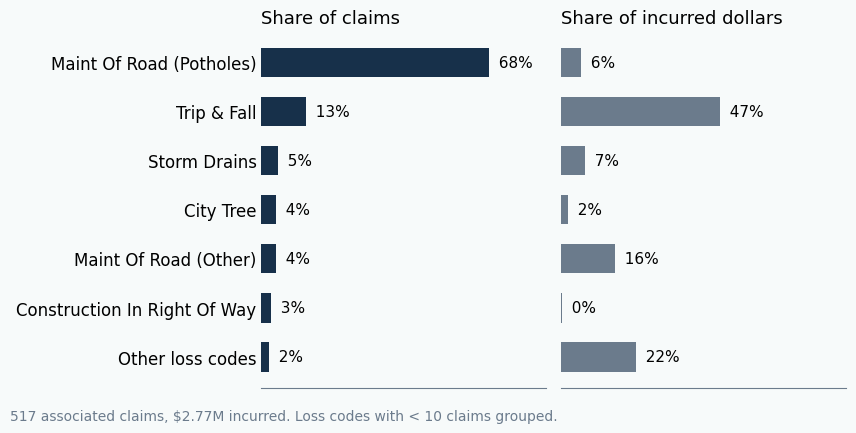

In [22]:
g = liab.groupby('loss_code_desc').agg(claims=('claim_id', 'size'), dollars=('incurred_total', 'sum'))
small = g['claims'] < MIN_CELL
other = g[small].sum()
g = g[~small]
if other['claims'] >= MIN_CELL:
    g.loc['Other loss codes'] = other
share = (g / g.sum()).sort_values('claims')
print((share * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.3), sharey=True, facecolor=BG)
for ax, col, color, title in [(axes[0], 'claims', NAVY, 'Share of claims'),
                              (axes[1], 'dollars', SLATE, 'Share of incurred dollars')]:
    ax.set_facecolor(BG)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(SLATE)
    ax.barh(share.index, share[col], color=color, height=0.6)
    for i, v in enumerate(share[col]):
        ax.text(v, i, f'  {v:.0%}', va='center', fontsize=11)
    ax.set_xlim(0, share.max().max() * 1.25)
    ax.set_xticks([])
    ax.set_title(title, fontsize=13, loc='left')
    ax.tick_params(axis='y', length=0, labelsize=12)
footnote(fig, f'{len(liab)} associated claims, {money(liab["incurred_total"].sum())} incurred. '
              f'Loss codes with < {MIN_CELL} claims grouped.')
fig.savefig('loss_code_claims_vs_dollars.png', dpi=200, facecolor=BG)

In [23]:
liab[liab['loss_code_desc'] == 'Trip & Fall'].groupby('loss_code_desc')[['claim_id','service_request_id_gid','service_name','incident_date','date_requested','incurred_total']]\
        .agg(
            n_claims=('claim_id','count'),
            n_services=('service_request_id_gid', 'count'),
            service_type=('service_name', lambda t: t.mode().tolist()[0]),
            earliest_incident_date=('incident_date','min'),
            latest_incident_date=('incident_date','max'),
            date_requested=('date_requested','min'),
            overall_incurred_total=('incurred_total','sum'),
    )

,n_claims,n_services,service_type,earliest_incident_date,latest_incident_date,date_requested,overall_incurred_total
loss_code_desc,,,,,,,
Trip & Fall,69,69,Sidewalk Repair Issue,2016-09-16,2024-10-15,2016-06-30,1300176.17


In [24]:
liab[liab['loss_code_desc'] == 'Trip & Fall'].groupby(['loss_code_desc','misrouted'])[['claim_id','service_request_id_gid','service_name','incident_date','date_requested','incurred_total']]\
        .agg(
            n_claims=('claim_id','count'),
            n_services=('service_request_id_gid', 'count'),
            service_type=('service_name', lambda t: t.mode().tolist()[0]),
            earliest_incident_date=('incident_date','min'),
            latest_incident_date=('incident_date','max'),
            date_requested=('date_requested','min'),
            overall_incurred_total=('incurred_total','sum'),
    )

n_claims  n_services           service_type  \
loss_code_desc misrouted                                                
Trip & Fall    False            65          65  Sidewalk Repair Issue   
               True              4           4   Pavement Maintenance   

                         earliest_incident_date latest_incident_date  \
loss_code_desc misrouted                                               
Trip & Fall    False                 2016-09-16           2024-10-15   
               True                  2022-05-03           2024-05-22   

                         date_requested  overall_incurred_total  
loss_code_desc misrouted                                         
Trip & Fall    False         2016-06-30              1210676.17  
               True          2021-09-07                89500.00

         Open before the incident  Unresolved after the incident
≤1 wk                         198                            118
1–4 wk                        136                            177
1–3 mo                         55                             61
3–12 mo                        65                             61
>1 yr                          63                            100


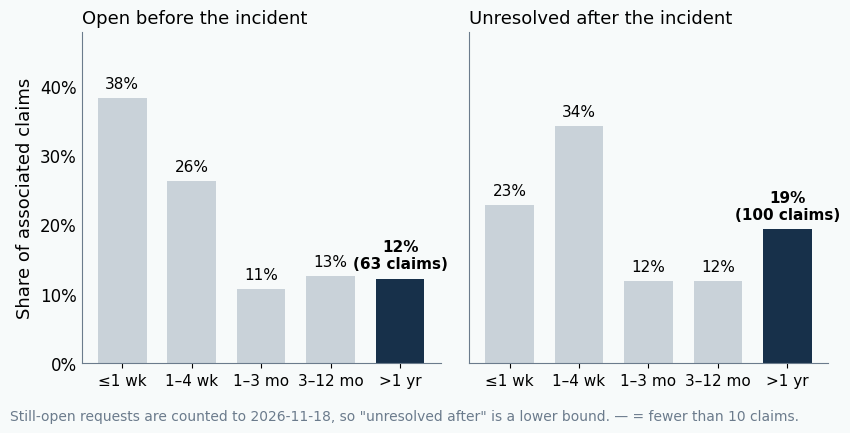

In [25]:
BINS   = [0, 7, 30, 90, 365, np.inf]
LABELS = ['≤1 wk', '1–4 wk', '1–3 mo', '3–12 mo', '>1 yr']
HIGHLIGHT = '>1 yr'
PANELS = [('lead_days', 'Open before the incident', NAVY),
          ('days_unresolved_after_incident', 'Unresolved after the incident', NAVY)]

counts = pd.DataFrame({title: pd.cut(liab[col], BINS, labels=LABELS).value_counts(sort=False)
                       for col, title, _ in PANELS})
print(counts)
shares = (counts / counts.sum()).where(counts >= MIN_CELL)

fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.3), sharey=True, facecolor=BG)
x = np.arange(len(LABELS))
for ax, (col, title, color) in zip(axes, PANELS):
    ax.set_facecolor(BG)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_color(SLATE)
    ax.set_axisbelow(True)
    s, n = shares[title], counts[title]
    ax.bar(x, s.fillna(0), width=0.7, color=[color if l == HIGHLIGHT else LIGHT for l in LABELS])
    for xi, l, v, k in zip(x, LABELS, s, n):
        if np.isnan(v):
            text = '—'
        elif l == HIGHLIGHT:
            text = f'{v:.0%}\n({k} claims)'
        else:
            text = f'{v:.0%}'
        ax.text(xi, (0 if np.isnan(v) else v) + 0.01, text, ha='center', va='bottom', fontsize=11,
                fontweight='bold' if l == HIGHLIGHT else 'normal')
    ax.set_xticks(x, LABELS, fontsize=11)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title(title, fontsize=13, loc='left')
    # ax.grid(axis='y', color=GRID, lw=0.8)
    ax.tick_params(axis='y', length=0)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel('Share of associated claims', fontsize=13)
axes[0].set_ylim(0, shares.max().max() * 1.25)
footnote(fig, f'Still-open requests are counted to {DATA_AS_OF}, so "unresolved after" is a lower bound. '
              f'— = fewer than {MIN_CELL} claims.')
fig.savefig('liab_timing_facets.png', dpi=200, facecolor=BG)

top 10 claims hold 64% of associated dollars | misrouted claims in the top 10: 1


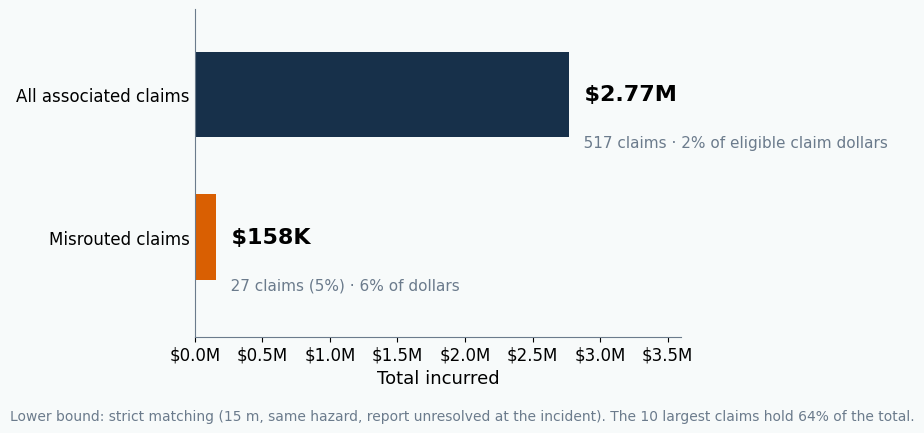

In [26]:
TOP_K = 10
amt, mis = liab['incurred_total'], liab['misrouted']
top_ids = amt.nlargest(TOP_K).index
top_share = amt[top_ids].sum() / amt.sum()
bars = [('All associated claims', amt.sum(), len(liab), NAVY),
        ('Misrouted claims', amt[mis].sum(), int(mis.sum()), ORANGE)]
print(f'top {TOP_K} claims hold {top_share:.0%} of associated dollars | '
      f'misrouted claims in the top {TOP_K}: {int(mis[top_ids].sum())}')

fig, ax = new_chart()
for i, (name, total, n, color) in enumerate(bars):
    ax.barh(i, total, color=color, height=0.6)
    ax.text(total, i, f'  {money(total)}', va='center', fontsize=16, fontweight='bold')
    if i == 0:
        sub = f'   {n:,} claims · {total / eligible["incurred_total"].sum():.0%} of eligible claim dollars'
    else:
        sub = f'   {n:,} claims ({n / len(liab):.0%}) · {total / amt.sum():.0%} of dollars'
    ax.text(total, i + 0.34, sub, va='center', fontsize=11, color=SLATE)
ax.set_yticks(range(len(bars)), [b[0] for b in bars], fontsize=12)
ax.set_ylim(len(bars) - 0.3, -0.6)
ax.set_xlim(0, bars[0][1] * 1.3)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(
    lambda v, _: f'${v / 1e6:,.1f}M' if bars[0][1] >= 1e6 else f'${v / 1e3:,.0f}K'))
ax.set_xlabel('Total incurred', fontsize=13)
# ax.grid(axis='x', color=GRID, lw=0.8)
# ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0)
footnote(fig, f'Lower bound: strict matching (15 m, same hazard, report unresolved at the incident). '
              f'The {TOP_K} largest claims hold {top_share:.0%} of the total.')
fig.savefig('incurred_totals.png', dpi=200, facecolor=BG)

                       size_ok  size_mis  median_ok  median_mis  extra_days
service_name                                                               
Street Flooded          2760.0    2635.0        0.0         1.0         1.0
Tree Maintenance       15543.0   32200.0        8.0        12.0         4.0
Pothole                41882.0   54736.0        4.0         9.0         5.0
Sidewalk Repair Issue   9013.0   15984.0        7.0        85.0        78.0
Pothole: Mann-Whitney p = 0.0000
Sidewalk Repair Issue: Mann-Whitney p = 0.0000
Street Flooded: Mann-Whitney p = 0.0000
Tree Maintenance: Mann-Whitney p = 0.0000


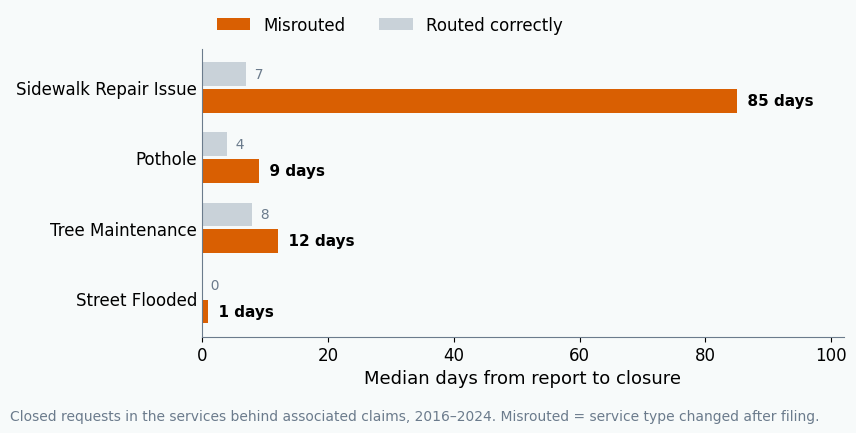

In [27]:
MIN_GROUP = 30

hazard_services = liab['service_name'].dropna().unique()
years = liab['date_requested'].dt.year

req = public[public['service_name'].isin(hazard_services)
             & public['status'].eq('Closed') & public['date_closed'].notna()
             & public['date_requested'].dt.year.between(years.min(), years.max())].copy()
req = req.merge(types, left_on='service_request_id', right_on='CASENUMBER', how='inner')
req['misrouted'] = (
    (req['CURRENT_TYPE'] != req['ORIGINAL_TYPE'])
    & ~((req['CURRENT_TYPE'] == 'Sidewalk Repair Issue') & (req['ORIGINAL_TYPE'] == 'Sidewalk')))
req['days_open'] = (req['date_closed'] - req['date_requested']).dt.days
req = req[req['days_open'] >= 0]

g = req.groupby(['service_name', 'misrouted'])['days_open'].agg(['size', 'median']).unstack()
g = g[(g['size'] >= MIN_GROUP).all(axis=1)]
g.columns = [f'{a}_{"mis" if b else "ok"}' for a, b in g.columns]
g['extra_days'] = g['median_mis'] - g['median_ok']
g = g.sort_values('extra_days')
print(g)
for svc, grp in req[req['service_name'].isin(g.index)].groupby('service_name'):
    a, b = grp.loc[grp['misrouted'], 'days_open'], grp.loc[~grp['misrouted'], 'days_open']
    print(f'{svc}: Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.4f}')

fig, ax = new_chart()
y = np.arange(len(g)); h = 0.38
ax.barh(y + h / 2, g['median_ok'], height=h - 0.04, color=LIGHT, label='Routed correctly')
ax.barh(y - h / 2, g['median_mis'], height=h - 0.04, color=ORANGE, label='Misrouted')
for yi, ok, mis_ in zip(y, g['median_ok'], g['median_mis']):
    ax.text(mis_, yi - h / 2, f'  {mis_:.0f} days', va='center', fontsize=11, fontweight='bold')
    ax.text(ok, yi + h / 2, f'  {ok:.0f}', va='center', fontsize=10, color=SLATE)
ax.set_yticks(y, g.index, fontsize=12)
ax.set_xlabel('Median days from report to closure', fontsize=13)
ax.set_xlim(0, g[['median_ok', 'median_mis']].max().max() * 1.2)
# ax.grid(axis='x', color=GRID, lw=0.8)
# ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.tick_params(axis='y', length=0)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=12, reverse=True)
footnote(fig, f'Closed requests in the services behind associated claims, {years.min()}–{years.max()}. '
              f'Misrouted = service type changed after filing.')
fig.savefig('hazard_days_open.png', dpi=200, facecolor=BG)

Share of claims: 5.2%
Share of incurred dollars: 5.7%
Expected share of dollars (same loss-code mix): 9.0%


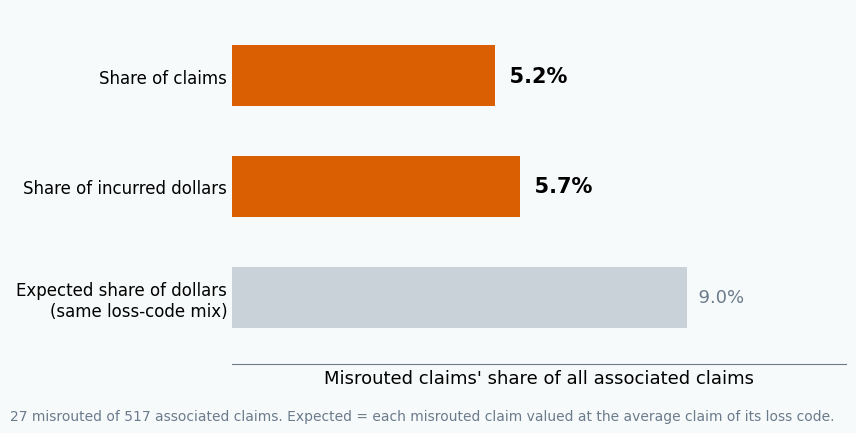

In [28]:
amt, mis = liab['incurred_total'], liab['misrouted']

# expected dollars: each misrouted claim valued at the average claim of its loss code among other associated claims
avg_other = liab[~mis].groupby('loss_code_desc')['incurred_total'].mean()
expected_dollars = liab.loc[mis, 'loss_code_desc'].map(avg_other).fillna(amt[~mis].mean()).sum()

rows = [('Share of claims', mis.mean(), ORANGE),
        ('Share of incurred dollars', amt[mis].sum() / amt.sum(), ORANGE),
        ('Expected share of dollars\n(same loss-code mix)', expected_dollars / amt.sum(), LIGHT)]
for name, v, _ in rows:
    print(f'{name.replace(chr(10), " ")}: {v:.1%}')

fig, ax = new_chart()
for i, (name, v, color) in enumerate(rows):
    ax.barh(i, v, color=color, height=0.55)
    ax.text(v, i, f'  {v:.1%}', va='center', fontsize=15 if color == ORANGE else 13,
            fontweight='bold' if color == ORANGE else 'normal', color='black' if color == ORANGE else SLATE)
ax.set_yticks(range(len(rows)), [r[0] for r in rows], fontsize=12)
ax.set_ylim(len(rows) - 0.4, -0.6)
ax.set_xlim(0, max(r[1] for r in rows) * 1.35)
ax.set_xticks([])                                   # bars carry their own labels
ax.set_xlabel('Misrouted claims\' share of all associated claims', fontsize=13)
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
footnote(fig, f'{int(mis.sum())} misrouted of {len(liab)} associated claims. Expected = each misrouted claim valued at the '
              f'average claim of its loss code.')
fig.savefig('misrouted_dollar_share.png', dpi=200, facecolor=BG)

In [29]:
n_years = liab['incident_date'].dt.year.max() - liab['incident_date'].dt.year.min() + 1
print(f'average per year over {n_years} years: all ${amt.sum() / n_years:,.0f} | misrouted ${amt[mis].sum() / n_years:,.0f}')

average per year over 9 years: all $307,710 | misrouted $17,589
